# Kalman Filter-Based Basket Trading Model

---

## Strategy Overview

| Parameter | Value |
|-----------|-------|
| **Universe** | 9 risk-on assets + 1 risk-off (TLT) |
| **Timeframe** | Daily (1D) |
| **Ranking** | Target prediction generated by Rolling Kalman Filter |
| **Selection** | Top 3 assets based on highest Kalman factor predictions |
| **Risk-Off** | TLT (20Y Treasury ETF) — absorbs unused weight |
| **Rebalancing** | Biweekly (every 10 trading days) |
| **Allocation** | Equal-weight among selected; remainder - TLT |
| **Lookahead** | 1-day signal shift — signal on day $t$, trade on day $t+1$ |

### Asset Universe

| # | Ticker | Asset | Role |
|---|--------|-------|------|
| 1 | BTC-USD | Bitcoin | Risk-on |
| 2 | QQQ | Nasdaq 100 ETF | Risk-on |
| 3 | SPY | S&P 500 ETF | Risk-on |
| 4 | AAPL | Apple | Risk-on |
| 5 | TSLA | Tesla | Risk-on |
| 6 | GLD | Gold ETF | Risk-on |
| 7 | NVDA | NVIDIA | Risk-on |
| 8 | AMZN | Amazon | Risk-on |
| 9 | XLE | Energy Sector ETF | Risk-on |
| 10 | **TLT** | **20Y Treasury ETF** | **Risk-off** |


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
import warnings
from collections import Counter
warnings.filterwarnings('ignore')

from pykalman import KalmanFilter

plt.rcParams.update({
    'figure.figsize': (16, 7),
    'axes.grid': True,
    'grid.alpha': 0.3,
    'font.size': 11,
    'axes.titleweight': 'bold',
    'axes.labelweight': 'bold',
    'figure.facecolor': 'white',
})

# -- STRATEGY PARAMETERS --------------------------------------
ALL_TICKERS   = ['BTC-USD', 'QQQ', 'SPY', 'AAPL', 'TSLA',
                 'GLD', 'NVDA', 'AMZN', 'XLE', 'TLT']
RISK_OFF      = 'TLT'
RISK_ON       = [t for t in ALL_TICKERS if t != RISK_OFF]

START_DATE    = '2018-01-01'
END_DATE      = '2025-01-01'

REBAL_PERIOD  = 10          # Biweekly
TOP_N         = 3           # Assets to hold
SIGNAL_LAG    = 1           # 1-day shift to prevent lookahead
INITIAL_CAP   = 100_000

print(f'Risk-on    : {len(RISK_ON)} assets — {RISK_ON}')
print(f'Risk-off   : {RISK_OFF}')
print(f'Period     : {START_DATE} to {END_DATE}')
print(f'Rebalance  : every {REBAL_PERIOD}d')
print(f'Signal lag : {SIGNAL_LAG}d (lookahead protection)')
print(f'Selection  : top {TOP_N} ranked by Kalman strength, remainder -> {RISK_OFF}')

Risk-on    : 9 assets — ['BTC-USD', 'QQQ', 'SPY', 'AAPL', 'TSLA', 'GLD', 'NVDA', 'AMZN', 'XLE']
Risk-off   : TLT
Period     : 2018-01-01 to 2025-01-01
Rebalance  : every 10d
Signal lag : 1d (lookahead protection)
Selection  : top 3 ranked by Kalman strength, remainder -> TLT


## 1. Data Download

In [2]:
# ============================================================
#  DOWNLOAD DAILY CLOSE PRICES
# ============================================================

close_prices = pd.DataFrame()
for ticker in ALL_TICKERS:
    df = yf.download(ticker, start=START_DATE, end=END_DATE,
                     progress=False, auto_adjust=True)
    if len(df) > 0:
        close_prices[ticker] = df['Close'].squeeze()

close_prices = close_prices.ffill().dropna()
returns = close_prices.pct_change().dropna()

print(f'Date range  : {close_prices.index[0].date()} to {close_prices.index[-1].date()}')
print(f'Trading days: {len(close_prices)}\n')
for t in close_prices.columns:
    role = 'RISK-OFF' if t == RISK_OFF else 'risk-on'
    pct = (close_prices[t].iloc[-1] / close_prices[t].iloc[0] - 1) * 100
    print(f'  {t:>8} [{role:>8}] | {close_prices[t].iloc[0]:>10,.2f} -> {close_prices[t].iloc[-1]:>10,.2f} | {pct:>+8.1f}%')

Date range  : 2018-01-02 to 2024-12-31
Trading days: 2556

   BTC-USD [ risk-on] |  14,982.10 ->  93,429.20 |   +523.6%
       QQQ [ risk-on] |     150.06 ->     507.45 |   +238.2%
       SPY [ risk-on] |     235.95 ->     576.22 |   +144.2%
      AAPL [ risk-on] |      40.23 ->     248.62 |   +517.9%
      TSLA [ risk-on] |      21.37 ->     403.84 |  +1789.9%
       GLD [ risk-on] |     125.15 ->     242.13 |    +93.5%
      NVDA [ risk-on] |       4.92 ->     133.94 |  +2624.0%
      AMZN [ risk-on] |      59.45 ->     219.39 |   +269.0%
       XLE [ risk-on] |      25.56 ->      40.88 |    +59.9%
       TLT [RISK-OFF] |      97.57 ->      81.12 |    -16.9%


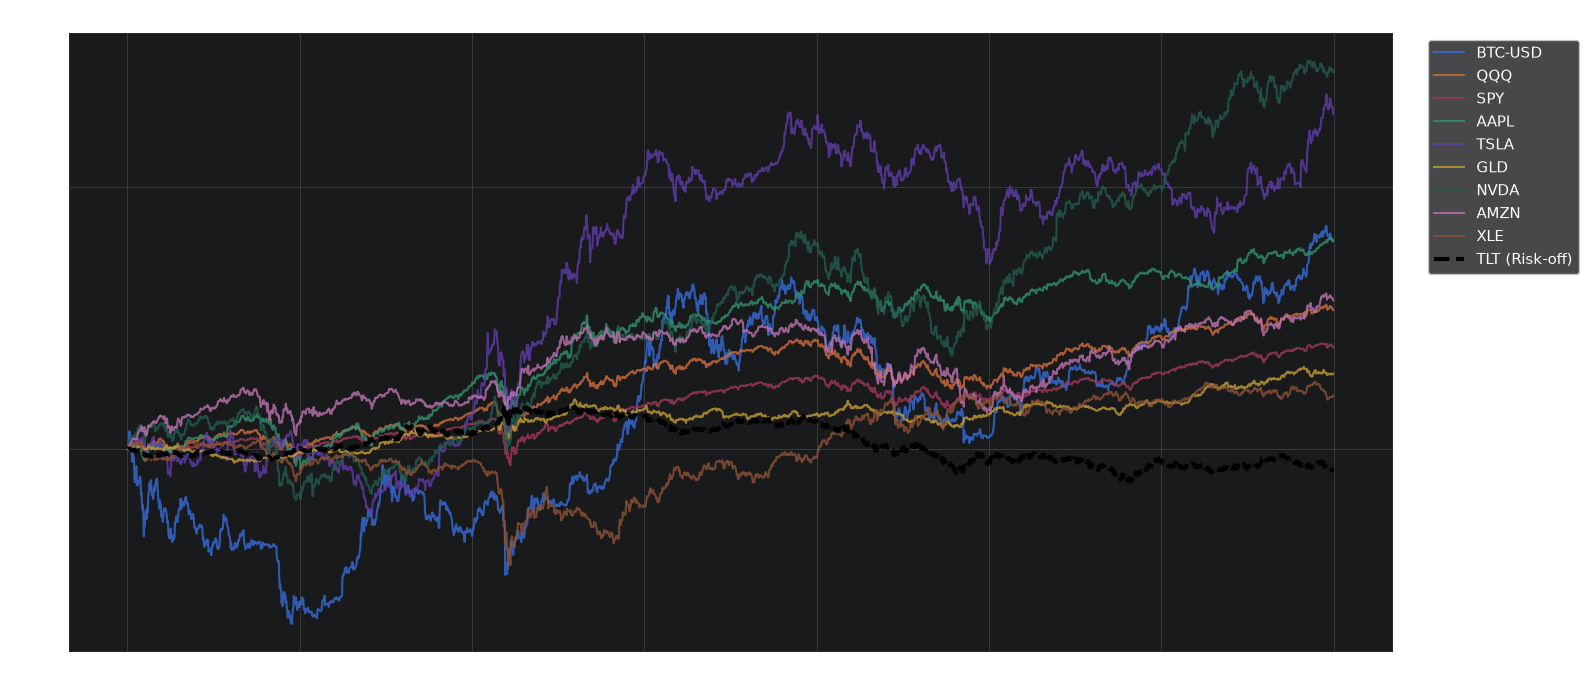

In [3]:
# ============================================================
#  PLOT NORMALIZED PRICES
# ============================================================
normalized = close_prices / close_prices.iloc[0] * 100

fig, ax = plt.subplots(figsize=(16, 7))
for t in RISK_ON:
    ax.plot(normalized.index, normalized[t], label=f'{t}', linewidth=1.5, alpha=0.8)
    
ax.plot(normalized.index, normalized[RISK_OFF], label=f'{RISK_OFF} (Risk-off)', 
        linewidth=3, color='black', linestyle='--')

ax.set_title('Normalized Asset Prices (Base 100)')
ax.set_ylabel('Normalized Price')
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1))
ax.set_yscale('log')
plt.tight_layout()
plt.show()

## 2. Kalman Filter Signal Generation
We apply a 1-dimensional Kalman Filter to each risk-on asset to extract an underlying smoothed "trend" or state. The momentum/trend strength will be used as the ranking metric.

In [4]:
# ============================================================
#  ROLLING KALMAN FILTER IMPLEMENTATION
# ============================================================

def get_kalman_trend(prices, window=60):
    """
    Calculates a rolling Kalman Filter state (trend) to strictly avoid lookahead bias.
    For each day t, it only uses data up to t to estimate the state at t.
    """
    n = len(prices)
    # Initialize Kalman Filter
    kf = KalmanFilter(
        transition_matrices=[1],
        observation_matrices=[1],
        initial_state_mean=prices.iloc[0],
        initial_state_covariance=1,
        observation_covariance=1,
        transition_covariance=0.01
    )
    
    # kf.filter() strictly uses past and current data for the state estimate at time t.
    # DO NOT use kf.smooth() as that introduces lookahead bias.
    state_means, _ = kf.filter(prices.values)
    
    return pd.Series(state_means.flatten(), index=prices.index)

# Calculate Kalman Trend for all Risk-On assets
kalman_trends = pd.DataFrame(index=close_prices.index)
kalman_signals = pd.DataFrame(index=close_prices.index)

for t in RISK_ON:
    # 1. Get Kalman estimated state (trend)
    kalman_trends[t] = get_kalman_trend(close_prices[t])
    
    # 2. Calculate a signal metric: e.g., Trend Momentum (current trend / trend 20 days ago - 1)
    kalman_signals[t] = kalman_trends[t].pct_change(20)
    
print("Kalman States calculated without lookahead bias.")


Kalman States calculated without lookahead bias.


## 3. Strategy Allocation & Lookahead Prevention
We shift the signals by 1 day (`SIGNAL_LAG = 1`) to ensure we do not trade on the same day the signal is generated. We rank assets based on their signal strength and perform biweekly rebalancing.

Target weights calculated. Forward filled over 10 day intervals with a 1-day lag.


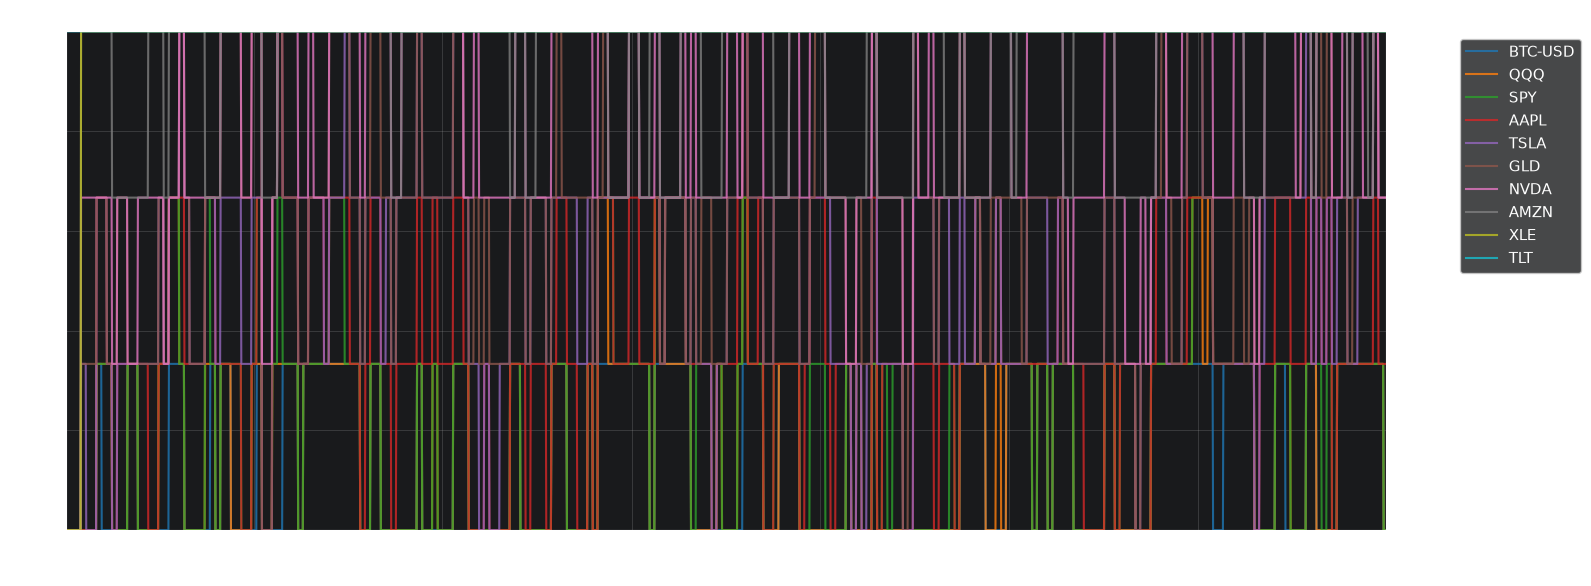

In [5]:
# ============================================================
#  RANKING, SELECTION, AND ALLOCATION
# ============================================================

# 1. SHIFT SIGNAL to prevent lookahead bias
# Signal calculated with data up to day t is applied for positions on day t+1
tradable_signals = kalman_signals.shift(SIGNAL_LAG)

# Initialize Portfolio Weights DataFrame with NaN so ffill() works correctly
target_weights = pd.DataFrame(np.nan, index=close_prices.index, columns=ALL_TICKERS)

# Generate list of rebalance dates (every REBAL_PERIOD days)
rebalance_dates = close_prices.index[::REBAL_PERIOD]

for date in rebalance_dates:
    if date not in tradable_signals.index:
        continue
        
    # Get signals for this rebalance day
    current_signals = tradable_signals.loc[date].dropna()
    
    # If not enough data to form signal, put everything in Risk-Off
    if len(current_signals) == 0:
        target_weights.loc[date, :] = 0.0
        target_weights.loc[date, RISK_OFF] = 1.0
        continue
        
    # 2. RANKING & SELECTION
    # Sort assets by highest Kalman trend momentum (ascending=False)
    ranked_assets = current_signals.sort_values(ascending=False)
    
    # Select top N assets.
    top_assets = ranked_assets.head(TOP_N)
    
    # 3. ALLOCATION
    held_assets = top_assets.index.tolist()
    weight_per_asset = 1.0 / TOP_N
    
    target_weights.loc[date, :] = 0.0
    for asset in held_assets:
        target_weights.loc[date, asset] = weight_per_asset

    # Leftover weight (if fewer than TOP_N assets chosen) goes to RISK_OFF
    allocated_weight = len(held_assets) * weight_per_asset
    leftover = max(0.0, 1.0 - allocated_weight)
    target_weights.loc[date, RISK_OFF] += leftover

# Forward fill weights between rebalance periods (NaN rows become the prior rebalance's weights)
target_weights = target_weights.ffill()

# Any remaining NaN (days before the first rebalance signal) -> 100% RISK_OFF
target_weights = target_weights.fillna(0.0)
mask = np.isclose(target_weights.sum(axis=1), 0.0)
target_weights.loc[mask, RISK_OFF] = 1.0

# Sanity check: sum of weights should be 1.0 on every day
assert np.allclose(target_weights.sum(axis=1), 1.0), "Weights do not sum to 1.0"

print(f"Target weights calculated. Forward filled over {REBAL_PERIOD} day intervals with a {SIGNAL_LAG}-day lag.")

# Plot weights over time to visualize allocation
target_weights.plot(figsize=(16, 6), stacked=True, colormap='tab10', alpha=0.8)
plt.title('Portfolio Allocation Weights Over Time')
plt.ylabel('Weight')
plt.ylim(0, 1)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


## 4. Backtesting & Performance Evaluation
Calculate portofolio daily returns by multiplying the target weights by the asset daily returns. Then we calculate cumulative returns and benchmark against an equal-weight portfolio and the S&P 500 (SPY).

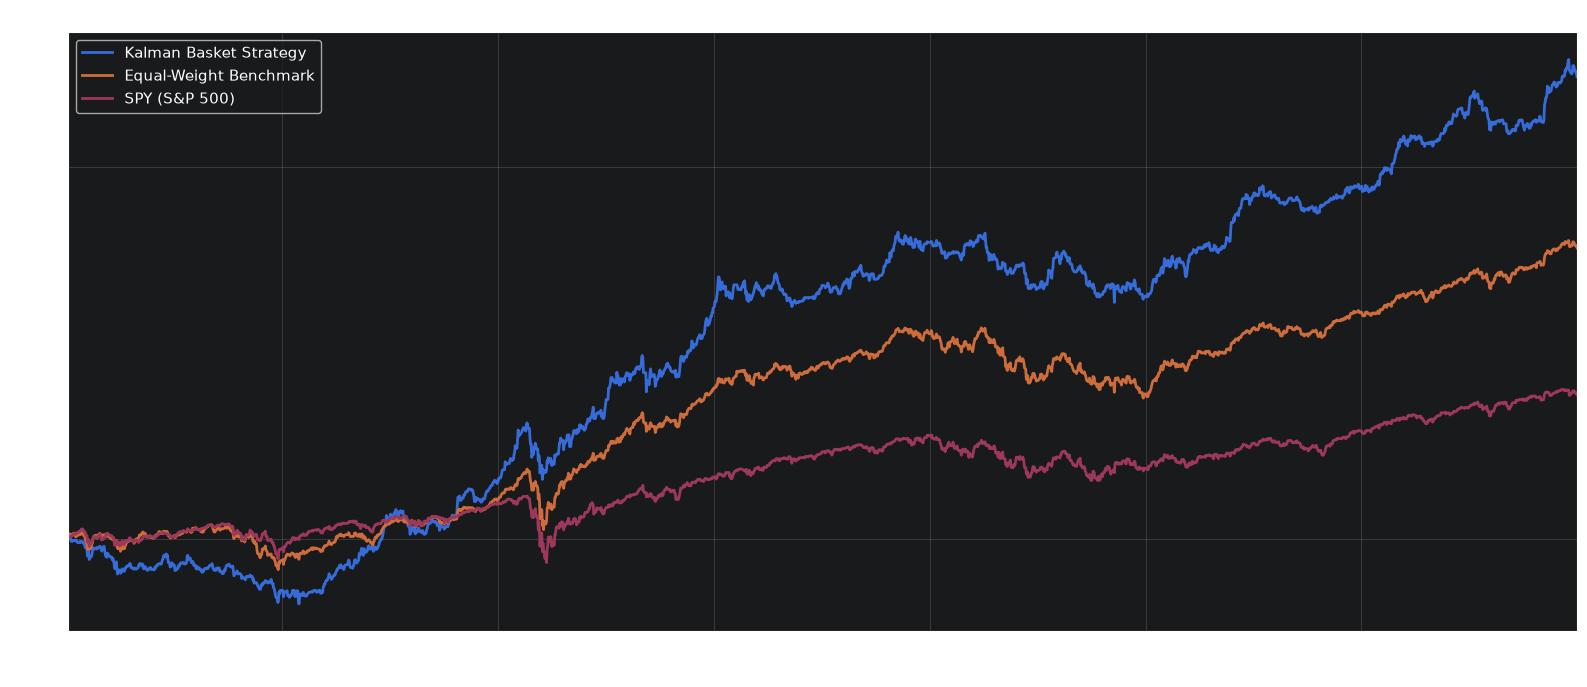

,Kalman Basket Strategy,Equal-Weight Benchmark,SPY (S&P 500)
Total Return,1644.75%,506.46%,144.21%
CAGR,32.56%,19.46%,9.21%
Ann. Volatility,26.35%,18.75%,16.16%
Sharpe Ratio,1.24,1.04,0.57
Max Drawdown,-35.21%,-35.23%,-33.72%


In [6]:
# ============================================================
#  CALCULATE PORTFOLIO RETURNS
# ============================================================

# Portfolio daily return is weight * asset_return
# Note: weights at time t are applied to returns at time t since returns[t] = price[t]/price[t-1] - 1
# And target_weights are already correctly shifted inherently via the signal shift logic acting upon data[t-1].
portfolio_returns = (target_weights * returns).sum(axis=1)

# Calculate Equity Curves
strats = pd.DataFrame(index=returns.index)
strats['Kalman Basket Strategy'] = (1 + portfolio_returns).cumprod() * INITIAL_CAP
strats['Equal-Weight Benchmark'] = (1 + returns.mean(axis=1)).cumprod() * INITIAL_CAP
strats['SPY (S&P 500)'] = (1 + returns['SPY']).cumprod() * INITIAL_CAP

# Plot Equity Curves
strats.plot(figsize=(16, 7), linewidth=2)
plt.title('Kalman Basket Model Strategy vs. Benchmarks')
plt.ylabel('Portfolio Value ($)')
plt.yscale('log')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

# ============================================================
#  PERFORMANCE METRICS
# ============================================================

def calc_metrics(returns_series, periods=252):
    cum_ret = (1 + returns_series).prod() - 1
    
    years = len(returns_series) / periods
    cagr = (1 + cum_ret) ** (1/years) - 1
    
    vol = returns_series.std() * np.sqrt(periods)
    sharpe = cagr / vol if vol != 0 else 0
    
    roll_max = (1 + returns_series).cumprod().cummax()
    drawdown = (1 + returns_series).cumprod() / roll_max - 1
    max_dd = drawdown.min()
    
    return pd.Series({
        'Total Return': f"{cum_ret*100:.2f}%",
        'CAGR': f"{cagr*100:.2f}%",
        'Ann. Volatility': f"{vol*100:.2f}%",
        'Sharpe Ratio': f"{sharpe:.2f}",
        'Max Drawdown': f"{max_dd*100:.2f}%"
    })

metrics_df = pd.DataFrame({
    'Kalman Basket Strategy': calc_metrics(portfolio_returns),
    'Equal-Weight Benchmark': calc_metrics(returns.mean(axis=1)),
    'SPY (S&P 500)': calc_metrics(returns['SPY'])
})

display(metrics_df)